# 01_EDA — Exploratory Data Analysis

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\project-1-refugee-integration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
master = pd.read_parquet('data/processed/refugee_master_consolidated.parquet')
print(f'Shape: {master.shape}')
print(f'Columns: {len(master.columns)}')

Shape: (29506, 27)
Columns: 27


In [4]:
print('Integration Index Distribution:')
print(master['integration_index'].describe().round(2))

Integration Index Distribution:
count    29506.00
mean        54.12
std          8.64
min         28.40
25%         48.30
50%         53.74
75%         59.92
max         79.50
Name: integration_index, dtype: float64


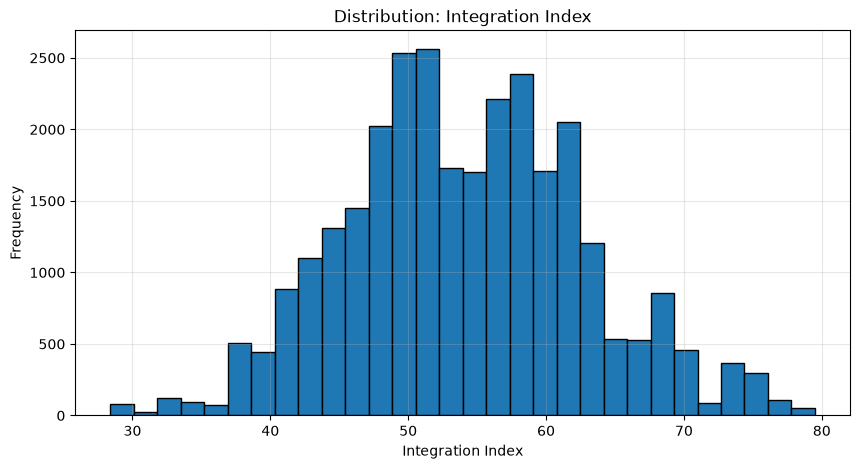

In [5]:
plt.figure(figsize=(10, 5))
plt.hist(master['integration_index'], bins=30, edgecolor='black')
plt.title('Distribution: Integration Index')
plt.xlabel('Integration Index')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

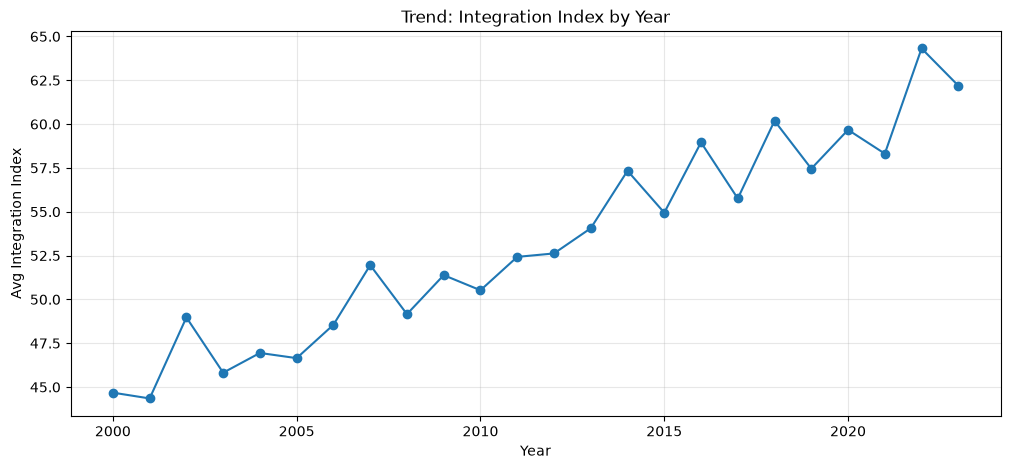

In [6]:
yearly_avg = master.groupby('Year')['integration_index'].mean()
plt.figure(figsize=(12, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker='o')
plt.title('Trend: Integration Index by Year')
plt.xlabel('Year')
plt.ylabel('Avg Integration Index')
plt.grid(True, alpha=0.3)
plt.show()

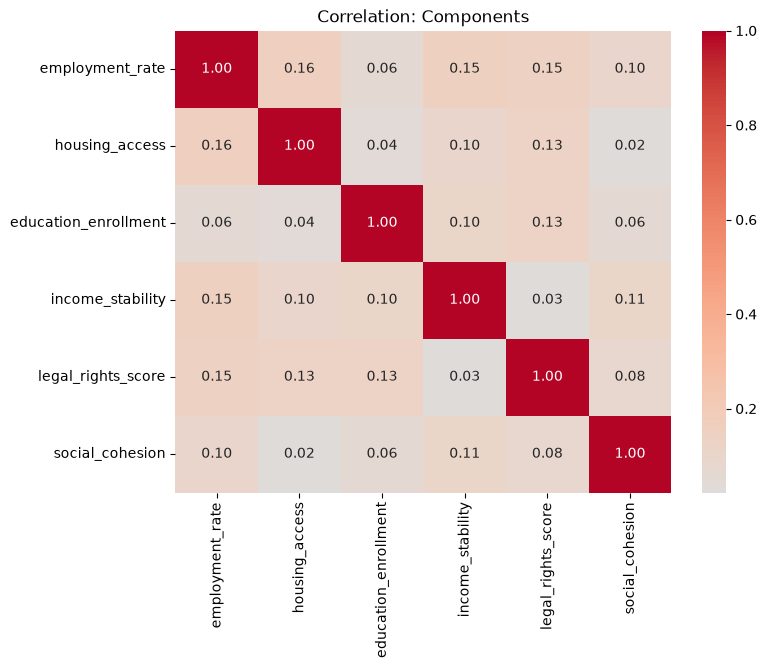

In [7]:
components = ['employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion']
corr = master[components].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation: Components')
plt.show()

In [8]:
print('Top 10 countries:')
print(master.groupby('country_name')['integration_index'].mean().nlargest(10).round(2))

Top 10 countries:
country_name
Brunei        58.41
Armenia       58.16
Costa Rica    57.23
Bahamas       56.89
Brazil        56.82
Belize        56.33
Albania       56.00
Algeria       55.93
Argentina     55.78
Cyprus        55.78
Name: integration_index, dtype: float64
